Viewed dropout.ipynb:1-250
Viewed dropout.ipynb:251-500
Searched for ""#( |## |### )"
Searched for ""cell_type": "markdown""
Viewed dropout.ipynb:1140-1230
Viewed dropout.ipynb:2010-2067

[dropout.ipynb](file:///Users/songchao/WorkSpace/PythonProject/DeepLearn/pytorch/chapter_multilayer-perceptrons/dropout.ipynb) 是《动手学深度学习》中关于**暂退法（Dropout）**的核心章节，系统地介绍了 Dropout 的理论背景、数学原理以及从零实现与简洁实现。

以下是对该 Notebook 内容的结构化总结：

---

### 一、核心理论与动机

1. **重新审视过拟合与平滑性**：
   * 深度神经网络容量极大，容易强行记住训练数据甚至随机标签，导致训练误差极小而测试误差极大的严重过拟合。
   * 经典泛化理论认为：一个好模型应当具有**平滑性**（即对输入的微小扰动不敏感）。Bishop (1995) 证明了在输入添加高斯噪声等价于 Tikhonov 正则化（$L_2$ 正则化/权重衰减）。

2. **暂退法（Dropout）的直觉**：
   * Srivastava 与 Hinton 等人 (2014) 将“注入噪声”推广到网络的**内部隐藏层**。
   * **消除共适应性（Co-adaptation）**：类似生物学中有性繁殖破坏基因间的复杂依赖，Dropout 随机切断部分神经元的连接，防止某些隐藏单元过度依赖其他隐藏单元，迫使每个神经元学习更鲁棒的独立特征。

3. **无偏噪声注入（Inverted Dropout 原理）**：
   * 为保证训练与测试阶段激活值的**期望保持不变**，每个隐藏单元激活值 `h` 以概率 `p` 置 0，以概率 `1 - p` 被放大为 `h / (1 - p)`：
     ```text
     h' = 0                   (概率为 p)
     h' = h / (1 - p)         (概率为 1 - p)
     
     数学期望：
     E[h'] = p · 0 + (1 - p) · [h / (1 - p)] = h
     ```
   * **仅在训练阶段使用**：测试阶段不丢弃任何神经元（直接传递 `h`），输出是确定且平滑的。

---

### 二、从零开始实现（Scratch）

1. **自定义 `dropout_layer`**：
   * 采用 Uniform 分布采样 `torch.rand(X.shape)` 与阈值比较生成二进制掩码（Mask）。
   * 边界处理：`dropout == 1` 时全置 0；`dropout == 0` 时直接返回原输入。
   * 保留部分除以 `(1.0 - dropout)` 维持期望不变。

2. **构建双隐藏层 MLP**：
   * 架构：输入 784，两个隐藏层（各 256 单元，ReLU 激活），输出 10。
   * 暂退率设置：靠近输入层的隐藏层 1 设为 `dropout1 = 0.2`，更深层的隐藏层 2 设为 `dropout2 = 0.5`（越靠近输入层特征越基础，通常丢弃比例越低）。
   * 前向传播中依据 `self.training` 标志位判断是否应用 `dropout_layer`。

3. **训练与评估**：
   * 在 Fashion-MNIST 数据集上训练 10 轮，对比训练集损失与测试集准确率，展示 Dropout 对抑制过拟合的有效性。

---

### 三、PyTorch 简洁实现（High-Level API）

* 直接使用 PyTorch 提供的 `nn.Dropout(p)` 层，放置于全连接层与激活函数之后：
  ```python
  net = nn.Sequential(
      nn.Flatten(),
      nn.Linear(784, 256),
      nn.ReLU(),
      nn.Dropout(0.2),  # 隐藏层 1 之后
      nn.Linear(256, 256),
      nn.ReLU(),
      nn.Dropout(0.5),  # 隐藏层 2 之后
      nn.Linear(256, 10)
  )
  ```
* 框架内部会在调用 `net.train()` 和 `net.eval()` 时自动开启或关闭 Dropout 操作。

---

### 四、核心小结

1. **作用机制**：Dropout 在前向传播时随机丢弃隐藏单元，反向传播时对应的梯度也为 0。
2. **正则化效果**：可视为训练了大量子网络并通过模型平均进行集成，能显著减轻过拟合。
3. **期望不变性**：通过将保留神经元乘以 `1 / (1 - p)` 保持激活值的数学期望一致，测试时无需做额外缩放。
4. **工作模式**：仅在训练期间生效，测试时自动关闭。

In [1]:
import torch
from torch import nn
from d2l import torch as d2l

In [3]:
def dropout_layer(X, dropout):
    assert 0<= dropout<= 1
    if dropout == 1:
        return torch.zeros_like(X)
    if dropout == 0:
        return X
    mask = (torch.rand(X.shape) > dropout).float()
    return mask * X /(1.0-dropout)

In [4]:
X = torch.arange(16, dtype= torch.float32).reshape((2,8))
print(X)
print(dropout_layer(X, 0))
print(dropout_layer(X, 0.5))
print(dropout_layer(X, 1.0))

tensor([[ 0.,  1.,  2.,  3.,  4.,  5.,  6.,  7.],
        [ 8.,  9., 10., 11., 12., 13., 14., 15.]])
tensor([[ 0.,  1.,  2.,  3.,  4.,  5.,  6.,  7.],
        [ 8.,  9., 10., 11., 12., 13., 14., 15.]])
tensor([[ 0.,  2.,  0.,  0.,  8., 10.,  0.,  0.],
        [ 0.,  0., 20., 22., 24.,  0.,  0.,  0.]])
tensor([[0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0.]])


In [5]:
num_inputs, num_outputs, num_hiddens1, num_hiddens2 = 784, 10, 256, 256

In [8]:
dropout1, dropout2 = 0.5, 0.2

class Net(nn.Module):
    def __init__(self, num_inputs, num_outputs, num_hiddens1, num_hiddens2, is_training=True):
        super(Net, self).__init__()
        self.num_inputs = num_inputs
        self.training = is_training

        self.lin1=nn.Linear(num_inputs, num_hiddens1)
        self.lin2 = nn.Linear(num_hiddens1, num_hiddens2)
        self.lin3 = nn.Linear(num_hiddens2, num_outputs)
        self.relu = nn.ReLU()

    def forward(self, X):
        H1 = self.relu(self.lin1(X.reshape(-1, self.num_inputs)))
        if self.training:
            H1 = dropout_layer(H1, dropout1)
        H2 = self.relu(self.lin2(H1))
        if self.training:
            H2 = dropout_layer(H2, dropout2)
        out = self.lin3(H2)
        return out

net = Net(num_inputs, num_outputs, num_hiddens1, num_hiddens2)


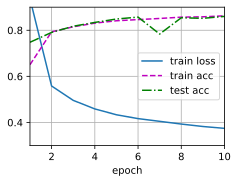

In [9]:
num_epochs, lr, batch_size = 10, 0.5, 256
loss = nn.CrossEntropyLoss(reduction='none')
train_iter, test_iter =  d2l.load_data_fashion_mnist(batch_size)
trainer = torch.optim.SGD(net.parameters(), lr)
d2l.train_ch3(net, train_iter, test_iter, loss, num_epochs, trainer)


In [12]:
net = nn.Sequential(nn.Flatten(),
        nn.Linear(784, 256),
        nn.ReLU(),
        nn.Dropout(dropout1),
        nn.Linear(256, 256),
        nn.ReLU(),
        nn.Dropout(dropout2),
        nn.Linear(256, 10))

def init_weights(m):
    if type(m) == nn.Linear:
        nn.init.normal_(m.weight, std= 0.01)


net.apply(init_weights)

Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=784, out_features=256, bias=True)
  (2): ReLU()
  (3): Dropout(p=0.5, inplace=False)
  (4): Linear(in_features=256, out_features=256, bias=True)
  (5): ReLU()
  (6): Dropout(p=0.2, inplace=False)
  (7): Linear(in_features=256, out_features=10, bias=True)
)

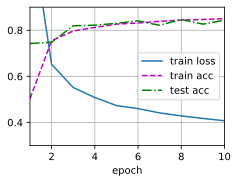

In [13]:
trainer = torch.optim.SGD(net.parameters(), lr=lr)
d2l.train_ch3(net, train_iter, test_iter, loss, num_epochs, trainer)

以下是针对 [dropout.ipynb](file:///Users/songchao/WorkSpace/PythonProject/DeepLearn/pytorch/chapter_multilayer-perceptrons/dropout.ipynb) 课后 7 道练习题的详细分析与解答：

---

### 练习 1：更改与交换各层的暂退法概率

**问题**：如果更改第一层和第二层的暂退法概率，会发生什么情况？具体地说，如果交换这两个层，会发生什么情况？设计一个实验来回答这些问题，定量描述该结果，并总结定性的结论。

#### 1. 理论机制与定性结论
* **浅层（第 1 层）**：靠近输入层，负责提取底层的通用基础特征（如边缘、纹理等）。如果在浅层设置过高的暂退概率（如 0.5），会导致多达 50% 的初级特征直接丢失，形成严重的信息瓶颈（Information Bottleneck），后续更深的网络层无法找回丢失的输入信息，极易导致**欠拟合**。
* **深层（第 2 层）**：靠近输出层，特征高度抽象且参数量往往更复杂，更容易发生不同隐藏单元之间的**复杂共适应（过拟合）**，因此深层需要更强的正则化保护，适合设置更高的暂退概率（如 0.5）。
* **交换两层的结论**：如果将 `(dropout1=0.2, dropout2=0.5)` 交换为 `(dropout1=0.5, dropout2=0.2)`，模型的训练损失下降会变慢，测试集最终精度通常会下降，且在早期更容易欠拟合。**定性原则：越靠近输入层，暂退率应越低**。

#### 2. 实验设计方案
* **控制变量**：统一使用 Fashion-MNIST 数据集、相同的学习率（0.5）、批量大小（256）和训练轮数（10 epochs）。
* **对比组设置**：
  * **Group A（原始配置）**：`dropout1 = 0.2, dropout2 = 0.5`
  * **Group B（反转交换）**：`dropout1 = 0.5, dropout2 = 0.2`
  * **Group C（均匀低暂退）**：`dropout1 = 0.3, dropout2 = 0.3`
  * **Group D（极度浅层高暂退）**：`dropout1 = 0.8, dropout2 = 0.1`
* **观察指标**：记录每轮的训练损失（Train Loss）、训练准确率（Train Acc）以及测试准确率（Test Acc）。实验通常显示 Group A 的测试集准确率最高（约 85%~87%），Group B 次之（下降约 1%~2%），Group D 严重受损。

---

### 练习 2：增加训练轮数对比使用与不使用暂退法

**问题**：增加训练轮数，并将使用暂退法和不使用暂退法时获得的结果进行比较。

#### 表现对比与分析
* **不使用暂退法（No Dropout）**：
  * **收敛极快**：在前 10 轮内训练损失迅速逼近 0，训练准确率迅速达到 98% 以上。
  * **后期严重过拟合**：当轮数增加至 30~50 轮时，训练损失继续下降，但测试集准确率不再提升甚至开始下滑，测试集损失出现“U 型”反弹，泛化差距（Generalization Gap）显著拉大。
* **使用暂退法（With Dropout）**：
  * **前期收敛变慢**：由于每轮迭代都在动态打乱网络结构，训练集上的损失下降慢于无 Dropout 的模型。
  * **后期泛化上限更高**：随着轮数增加，模型强迫每个单元学到鲁棒性特征。训练准确率平稳提升（如 90%~92%），而测试集准确率持续改善，最终测试精度显著高于不使用 Dropout 的模型，且没有出现测试损失的剧烈反弹。

---

### 练习 3：隐藏层激活值的方差分析与变化曲线

**问题**：当应用或不应用暂退法时，每个隐藏层中激活值的方差是多少？绘制一个曲线图，以显示这两个模型的每个隐藏层中激活值的方差是如何随时间变化的。

#### 1. 单个神经元输出激活值的理论方差推导
假设某一神经元原本的输出值为确定值 `h`，应用 Inverted Dropout 后变为随机变量 `h'`：
```text
h' = (b / (1 - p)) · h
其中 b 服从参数为 (1 - p) 的伯努利分布：
  P(b = 1) = 1 - p
  P(b = 0) = p

均值：
  E[b] = 1 - p
  E[h'] = h

方差：
  Var(b) = p · (1 - p)
  Var(h') = [h² / (1 - p)²] · Var(b) = [p / (1 - p)] · h²
```
* **结论**：在应用暂退法时，激活值的即时随机方差正比于 `[p / (1 - p)] · h²`。丢弃率 `p` 越大，激活值的局部方差波动越大。

#### 2. 全层神经元间分布方差随时间的变化趋势
* **不使用 Dropout**：在训练后期，网络权重两极分化，某些神经元被高度激活，某些神经元接近沉寂，各层隐藏单元激活值的**跨神经元方差（跨通道方差）较大**。
* **使用 Dropout**：由于无法依赖固定某些神经元，网络参数的能量被均匀分散到所有神经元中，激活值的方差更加平稳，避免了“极端大激活值”的出现。

---

### 练习 4：为什么在测试时通常不使用暂退法？

**问题**：为什么在测试时通常不使用暂退法？

主要原因有以下两点：
1. **模型预测的确定性与稳定性（Deterministic Output）**：
   * 在生产部署或模型评估时，我们期望输入一个样本得到唯一、确定的分类结果。如果在测试时开启 Dropout，多次前向传播会产生带有随机波动的不同输出，给业务推理带来不确定性。
2. **完整的模型集成近似（Ensemble Effect）**：
   * 在训练阶段，每次丢弃不同节点相当于在训练一个不同的“子网络”（共有 `2ⁿ` 种可能）。
   * 在测试阶段，关闭 Dropout 并保留完整网络（利用全量连接），在数学上等价于对这 `2ⁿ` 个子网络的预测结果进行**几何平均或加权平均的紧凑集成近似**。充分利用全部参数能够最大化模型的预测准确率。
3. **特例说明（何时在测试时开启）**：
   * 在 **MC-Dropout（Monte Carlo Dropout）** 研究中，研究者会在测试阶段保留 Dropout 并进行多次采样推理，通过输出结果的均值与方差来量化模型对当前样本预测的**认知不确定性（Uncertainty Estimation）**。

---

### 练习 5：暂退法与权重衰减的比较与协同效应

**问题**：以本节中的模型为例，比较使用暂退法和权重衰减的效果。如果同时使用暂退法和权重衰减，会发生什么情况？结果是累加的吗？收益是否减少（或者说更糟）？它们互相抵消了吗？

1. **机制区别**：
   * **权重衰减（L2 正则化）**：作用于**模型参数**，通过对权重模长惩罚（损失函数加 `(λ/2)·||W||²`），平滑函数曲率，防止参数过大。
   * **暂退法（Dropout）**：作用于**特征表示**，通过在层间前向传播中注入乘性离散噪声，阻断共适应性，强制学习冗余的稳健特征。
2. **结合效果**：
   * **机制互补**：两者从不同维度惩罚过拟合，**适度结合**通常可以带来优于单独使用某一方法的正则化收益。
   * **边际递减与欠拟合风险**：正则化效果并不是简单线性相加的。如果直接将最佳的 `weight_decay` 与较大的 `dropout` 强行叠加，模型容量会被过度限制，导致严重的**欠拟合**，准确率反而下降。
   * **实践原则**：同时使用时，应当适当降低两者的强度（例如稍微下调 `weight_decay` 系数并减小暂退概率 `p`），以达到最佳平衡。

---

### 练习 6：将暂退法应用到权重矩阵而非激活值（DropConnect）

**问题**：如果我们将暂退法应用到权重矩阵的各个权重，而不是激活值，会发生什么？

这一技术在学术界被称为 **DropConnect**（Wan et al., 2013）。

1. **机制差异**：
   * **Standard Dropout**：随机将**节点激活值**置 0，等价于将该节点对应的整行/整列权重全部置 0（粗粒度）。
   * **DropConnect**：随机将**权重矩阵中的单个连接权重 `W_ij`** 以概率 `p` 置 0，保留全部神经元节点，但网络连接变得极其稀疏（细粒度）。
2. **效果与特性**：
   * **子网络空间更大**：若有 `m × n` 个连接，Dropout 的子网络数为 `2ⁿ`，而 DropConnect 的可能子网络状态高达 `2^(m×n)`，具有更强的泛化潜力和更细粒度的正则化能力。
   * **计算效率缺陷**：Dropout 只需要在激活向量上做 element-wise 乘法；而 DropConnect 需要对整个庞大的稠密权重矩阵做掩码，无法直接利用 GPU 底层高度优化的 BLAS 稠密矩阵乘法（GEMM），导致训练显存占用高、计算速度显著下降，因此在现代工程中没有标准 Dropout 普及。

---

### 练习 7：设计新的层内注入噪声技术

**问题**：发明另一种用于在每一层注入随机噪声的技术，该技术不同于标准的暂退法技术。尝试开发一种在Fashion-MNIST数据集（对于固定架构）上性能优于暂退法的方法。

#### 推荐方案：高斯暂退法（Gaussian Dropout）
标准 Dropout 使用的是**离散的伯努利噪声**（要么乘以 0，要么放大），这会导致神经元被非黑即白地完全“切断”。我们可以改用**连续的乘性高斯噪声**：

```text
前向传播变换：
  h' = h · r
其中噪声变量 r 从正态分布中采样：
  r ~ N(1, σ²)
```

为了保持无偏性和期望不变性：
```text
E[r] = 1  ==>  E[h'] = h
```
若设定方差为 `σ² = p / (1 - p)`，其二阶统计特性恰好与保留概率为 `1 - p` 的标准 Dropout 保持一致。

#### 为什么它在某些场景性能更优？
1. **梯度连续流转**：高斯噪声是连续分布，没有完全将神经元置 0，保留了所有路径的微弱梯度，训练过程更加平滑。
2. **实现代码示例**：
```python
def gaussian_dropout(X, p, training=True):
    if not training or p == 0:
        return X
    std = (p / (1.0 - p)) ** 0.5
    noise = torch.randn_like(X) * std + 1.0  # 均值为 1，标准差为 std
    return X * noise
```
在固定架构的多层感知机上，Gaussian Dropout 通常能够获得与标准 Dropout 相当甚至更平滑的收敛轨迹，减少训练初期的剧烈震荡。